# Profiling dan EDA Dataset Geohazard Newswatch

Notebook ini membangun profil lengkap dari folder `data/`:
- jumlah artikel pada tahap pengumpulan, konsolidasi, QC, cleaning/deduplication, dan output akhir;
- distribusi delapan kategori bencana;
- distribusi portal berita;
- distribusi waktu publikasi;
- distribusi bahasa;
- pemeriksaan duplikasi, kualitas teks, URL, tanggal, dan missing values;
- profil gold set berlabel.

Semua angka dibaca langsung dari artefak CSV/JSON aktual.

In [1]:
from pathlib import Path
import json
import ast
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (12, 6)

ROOT = Path(r"D:\MAGANGHUB BATCH 3\Scraper\geolocation3")
DATA = ROOT / "data"

def read_csv(relative):
    return pd.read_csv(DATA / relative, encoding="utf-8-sig")

def parse_query_groups(value):
    if pd.isna(value):
        return []
    try:
        parsed = json.loads(str(value))
        if isinstance(parsed, list):
            return [str(v).strip() for v in parsed]
    except Exception:
        pass
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, (list, tuple)):
            return [str(v).strip() for v in parsed]
    except Exception:
        pass
    return [str(value).strip()] if str(value).strip() else []

HAZARDS = [
    "gunungapi", "gempabumi", "tsunami", "tanah_longsor",
    "likuefaksi", "abrasi_pantai", "penurunan_tanah",
    "semburan_gas_lumpur",
]

raw = {}
for path in sorted((DATA / "raw").glob("*.csv")):
    raw[path.name] = pd.read_csv(path, encoding="utf-8-sig")

newswatch_long = read_csv("interim/consolidation/newswatch_long.csv")
articles = read_csv("interim/consolidation/articles.csv")
preprocessed = read_csv("interim/quality_control/newswatch_preprocessed.csv")
qc_issues = read_csv("interim/quality_control/qc_issues.csv")
clean = read_csv("processed/articles_clean.csv")
indonesia = read_csv("processed/articles_indonesia.csv")
prompt = read_csv("processed/articles_prompt.csv")
goldset = read_csv("interim/goldset/goldset_labeled.csv")

print("Paket dan dataset berhasil dimuat.")

Paket dan dataset berhasil dimuat.


## 1. Ringkasan Funnel Pengumpulan dan Pemrosesan

,Tahap,Jumlah
0,Raw CSV - baris mentah,4457
1,Newswatch - baris panjang,4457
2,Artikel unik dari URL,4083
3,Setelah QC/preprocessing,4083
4,Setelah cleaning/dedup,4083
5,Hanya bahasa Indonesia/und,4053
6,Siap prompt (duplikasi tepat dihapus),4051
7,Gold set berlabel,200


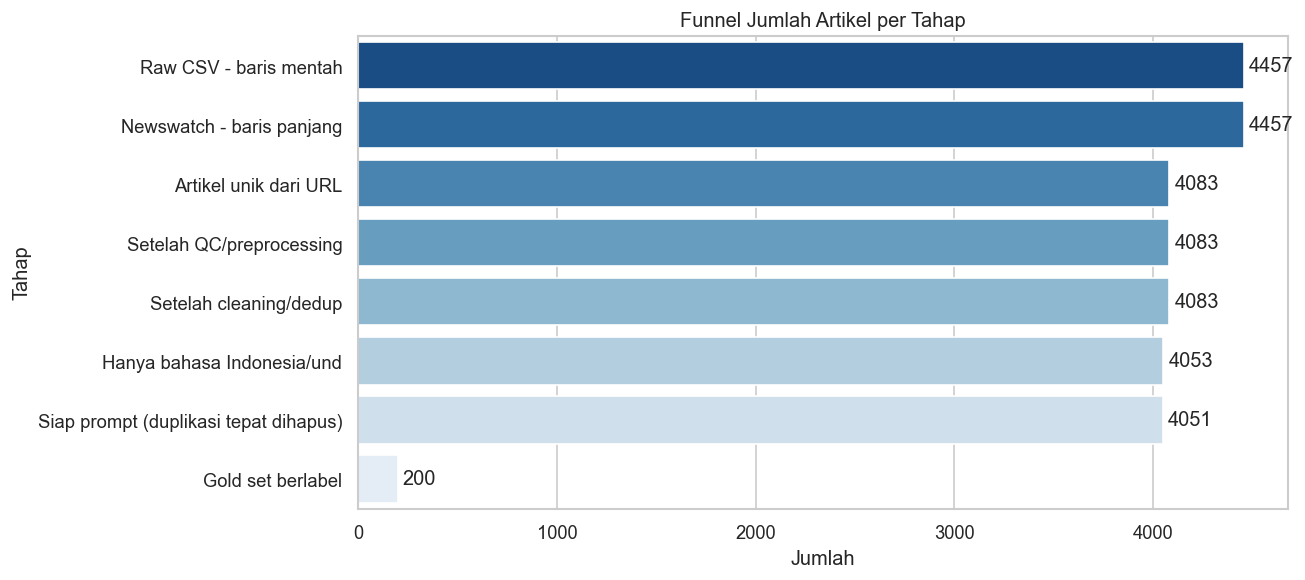

In [2]:
stage_counts = pd.DataFrame([
    ("Raw CSV - baris mentah", sum(len(df) for df in raw.values())),
    ("Newswatch - baris panjang", len(newswatch_long)),
    ("Artikel unik dari URL", len(articles)),
    ("Setelah QC/preprocessing", len(preprocessed)),
    ("Setelah cleaning/dedup", len(clean)),
    ("Hanya bahasa Indonesia/und", len(indonesia)),
    ("Siap prompt (duplikasi tepat dihapus)", len(prompt)),
    ("Gold set berlabel", len(goldset)),
], columns=["Tahap", "Jumlah"])

display(stage_counts)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=stage_counts, y="Tahap", x="Jumlah", ax=ax, palette="Blues_r")
ax.set_title("Funnel Jumlah Artikel per Tahap")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.tight_layout()
plt.show()

## 2. Profil Pengumpulan Raw

,sourcefile,rows,hazard
1,geohazard_02_gempabumi.csv,1306,gempabumi
2,geohazard_03_tsunami.csv,953,tsunami
0,geohazard_01_gunungapi.csv,605,gunungapi
4,geohazard_04_tanah_longsor.csv,410,tanah_longsor
3,geohazard_03_tsunami2.csv,240,tsunami2
8,geohazard_06_abrasi_pantai.csv,205,abrasi_pantai
12,geohazard_08_semburan_gas_lumpur.csv,123,semburan_gas_lumpur
13,geohazard_08_semburan_gas_lumpur2.csv,121,semburan_gas_lumpur2
6,geohazard_05_likuefaksi.csv,97,likuefaksi
9,geohazard_06_abrasi_pantai2.csv,93,abrasi_pantai2


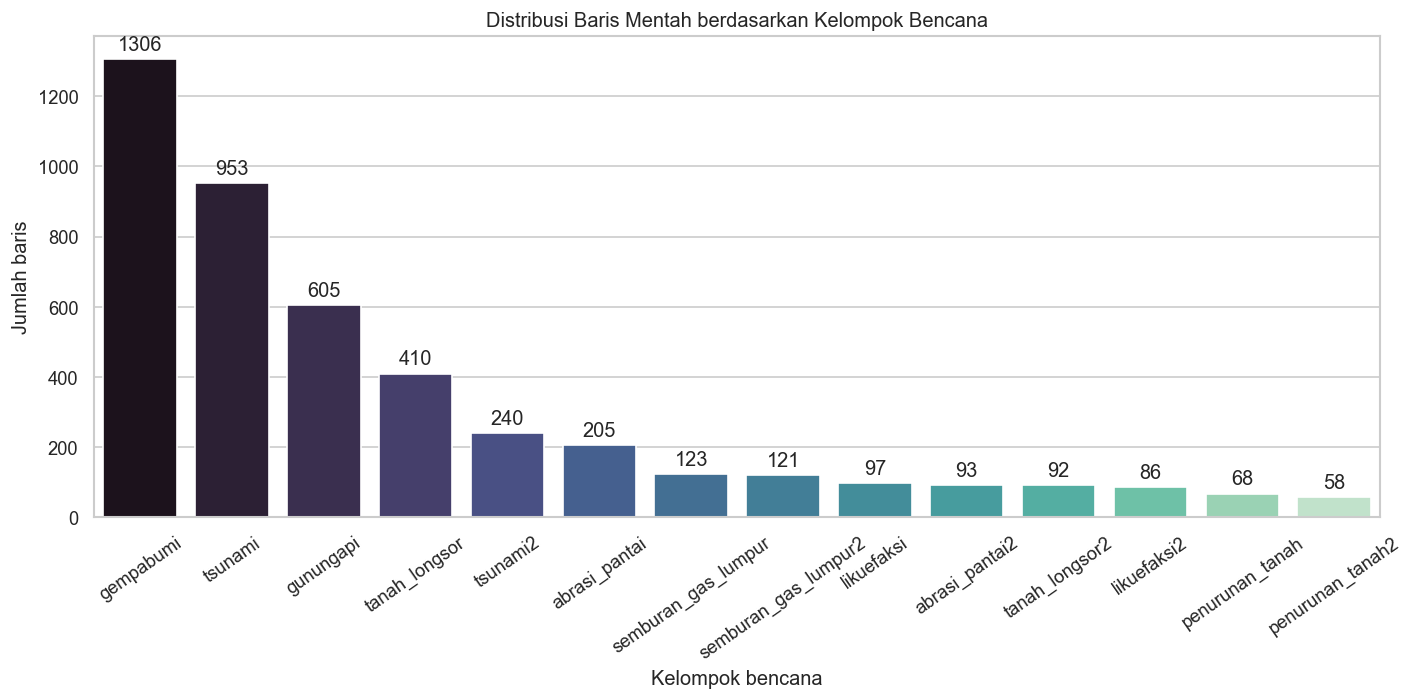

,Nilai
Rows sebelum concat,4457
Rows setelah concat,4457
Artikel unik setelah agregasi,4083
Rows teragregasi,374
Artikel multi-kueri,338
Grup konten duplikat lintas URL,2


In [3]:
raw_counts = pd.DataFrame({
    "sourcefile": list(raw.keys()),
    "rows": [len(df) for df in raw.values()],
})
raw_counts["hazard"] = raw_counts["sourcefile"].str.replace(r"^geohazard_\d+_", "", regex=True).str.replace(r"\d+$", "", regex=True).str.replace(r"\.csv$", "", regex=True)
raw_counts = raw_counts.sort_values("rows", ascending=False)

display(raw_counts)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=raw_counts, x="hazard", y="rows", ax=ax, palette="mako")
ax.set_title("Distribusi Baris Mentah berdasarkan Kelompok Bencana")
ax.set_xlabel("Kelompok bencana")
ax.set_ylabel("Jumlah baris")
ax.tick_params(axis="x", rotation=35)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
plt.tight_layout()
plt.show()

with open(DATA / "interim/consolidation/validation_report.json", encoding="utf-8") as f:
    validation_report = json.load(f)
pd.DataFrame([{
    "Rows sebelum concat": validation_report["rows_before_concat"],
    "Rows setelah concat": validation_report["rows_after_concat"],
    "Artikel unik setelah agregasi": validation_report["rows_after_article_aggregation"],
    "Rows teragregasi": validation_report["rows_collapsed_by_article_id"],
    "Artikel multi-kueri": validation_report["articles_in_multiple_query_groups"],
    "Grup konten duplikat lintas URL": validation_report["content_duplicate_groups_with_different_urls"],
}]).T.rename(columns={0:"Nilai"})

## 3. Distribusi Jenis Bencana

,jenis_bencana,jumlah,persen
0,gunungapi,605,14.817536
1,gempabumi,1277,31.276023
2,tsunami,1193,29.218712
3,tanah_longsor,502,12.294881
4,likuefaksi,183,4.481999
5,abrasi_pantai,298,7.298555
6,penurunan_tanah,126,3.085966
7,semburan_gas_lumpur,244,5.975998


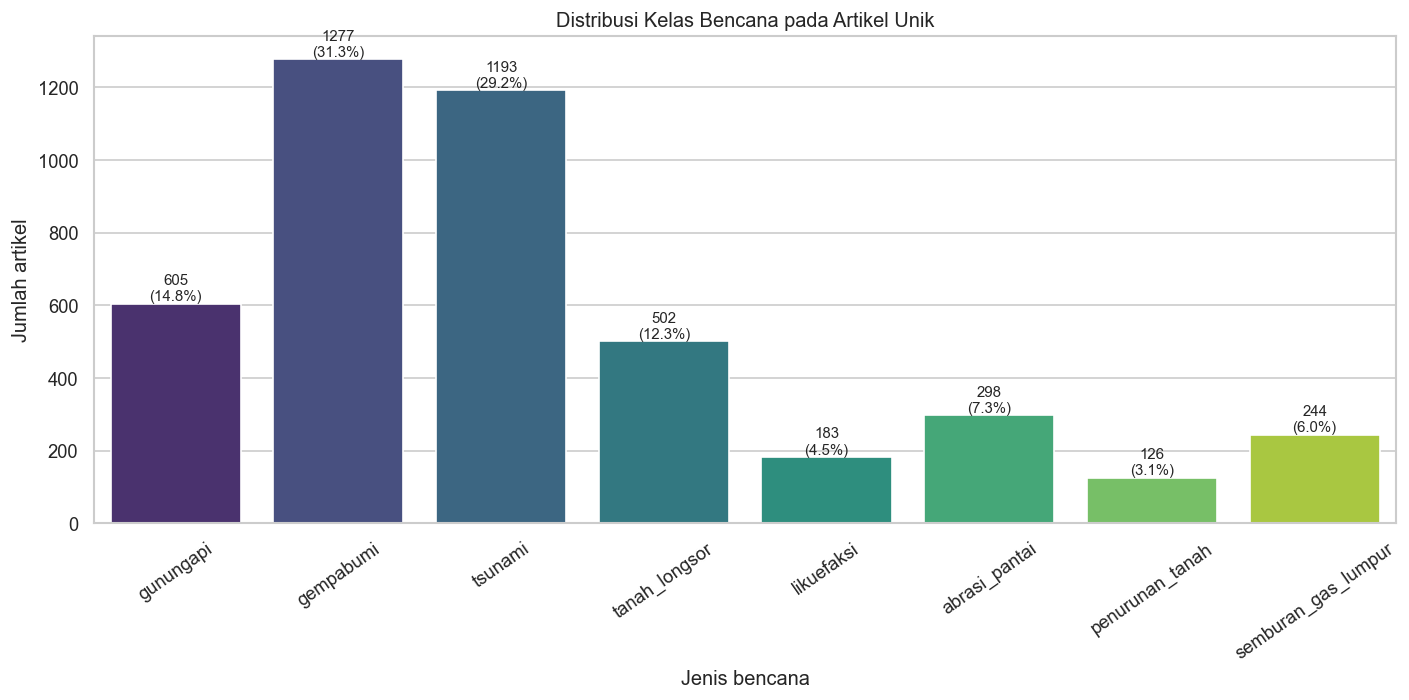

Artikel unik dengan multi-label kueri: 338 (8.28%)


In [4]:
article_groups = articles["query_group"].apply(parse_query_groups)
hazard_counts = pd.Series(
    [hazard for groups in article_groups for hazard in groups],
    name="bencana"
).value_counts().reindex(HAZARDS).fillna(0).astype(int)
hazard_df = hazard_counts.rename_axis("jenis_bencana").reset_index(name="jumlah")
hazard_df["persen"] = 100 * hazard_df["jumlah"] / len(articles)
display(hazard_df)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=hazard_df, x="jenis_bencana", y="jumlah", ax=ax, palette="viridis")
ax.set_title("Distribusi Kelas Bencana pada Artikel Unik")
ax.set_xlabel("Jenis bencana")
ax.set_ylabel("Jumlah artikel")
ax.tick_params(axis="x", rotation=35)
for i, row in hazard_df.iterrows():
    ax.text(i, row["jumlah"], f"{row['jumlah']}\n({row['persen']:.1f}%)",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

multi_label_count = article_groups.apply(len).gt(1).sum()
print(f"Artikel unik dengan multi-label kueri: {multi_label_count} "
      f"({100*multi_label_count/len(articles):.2f}%)")

## 4. Distribusi Portal Berita

,raw,artikel_unik,preprocessed,clean,indonesia,prompt,total_tahap
source,,,,,,,
www.metrotvnews.com,1027,951,951,951,949,948,5777
kompas.com,847,697,697,697,684,684,4306
antaranews.com,644,588,588,588,588,588,3584
jawapos.com,544,518,518,518,518,518,3134
liputan6.com,325,318,318,318,318,318,1915
republika.co.id,169,165,165,165,165,165,994
rri.co.id,144,143,143,143,138,138,849
harianjogja.com,140,137,137,137,137,137,825
beritasatu.com,133,126,126,126,126,126,763


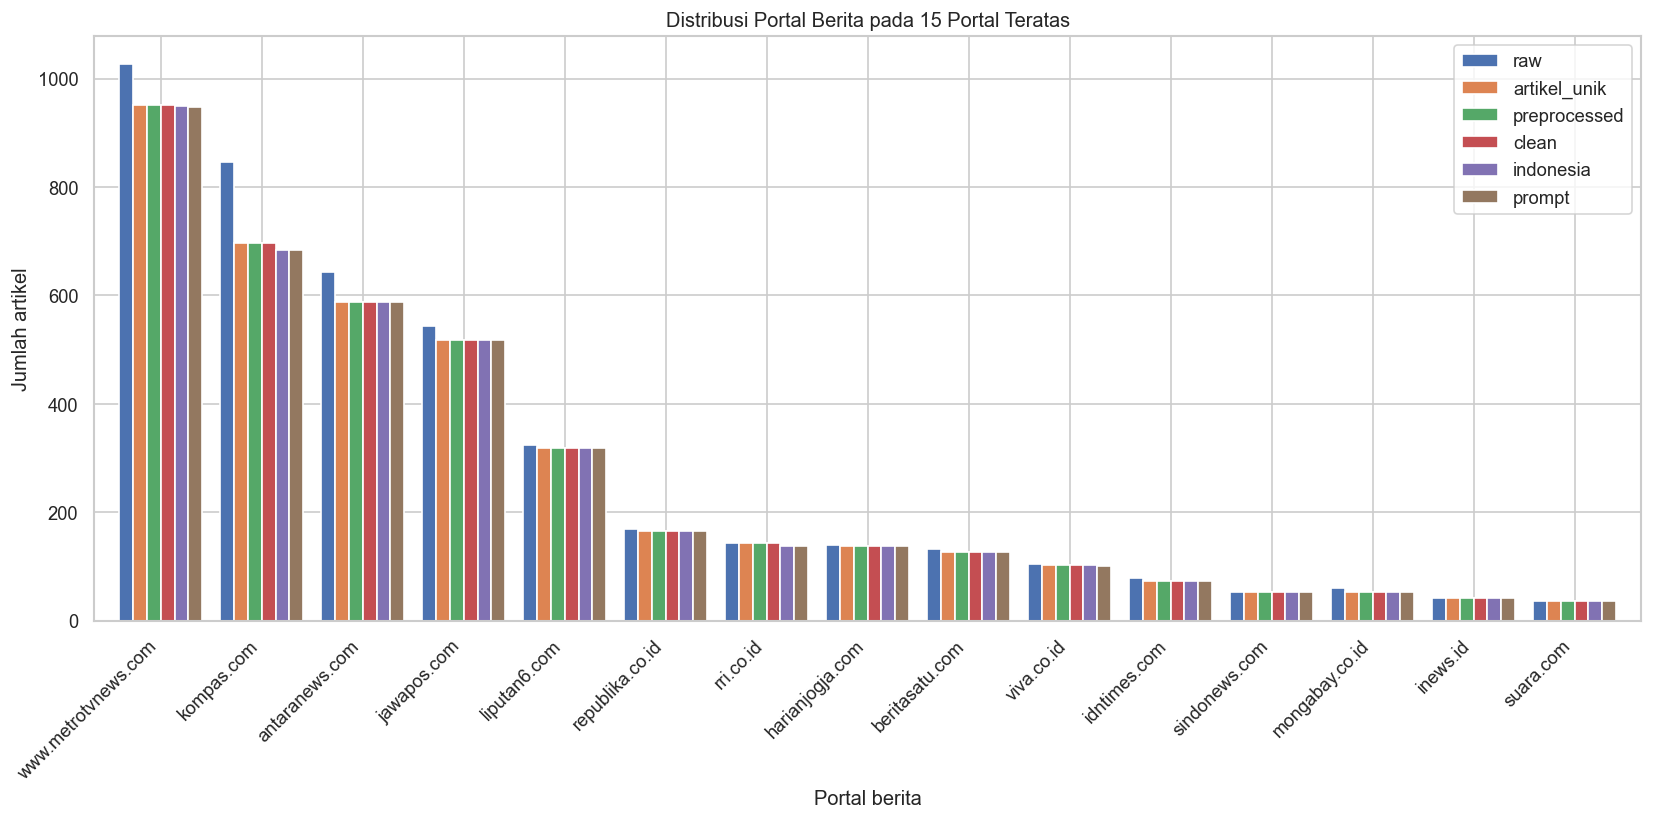

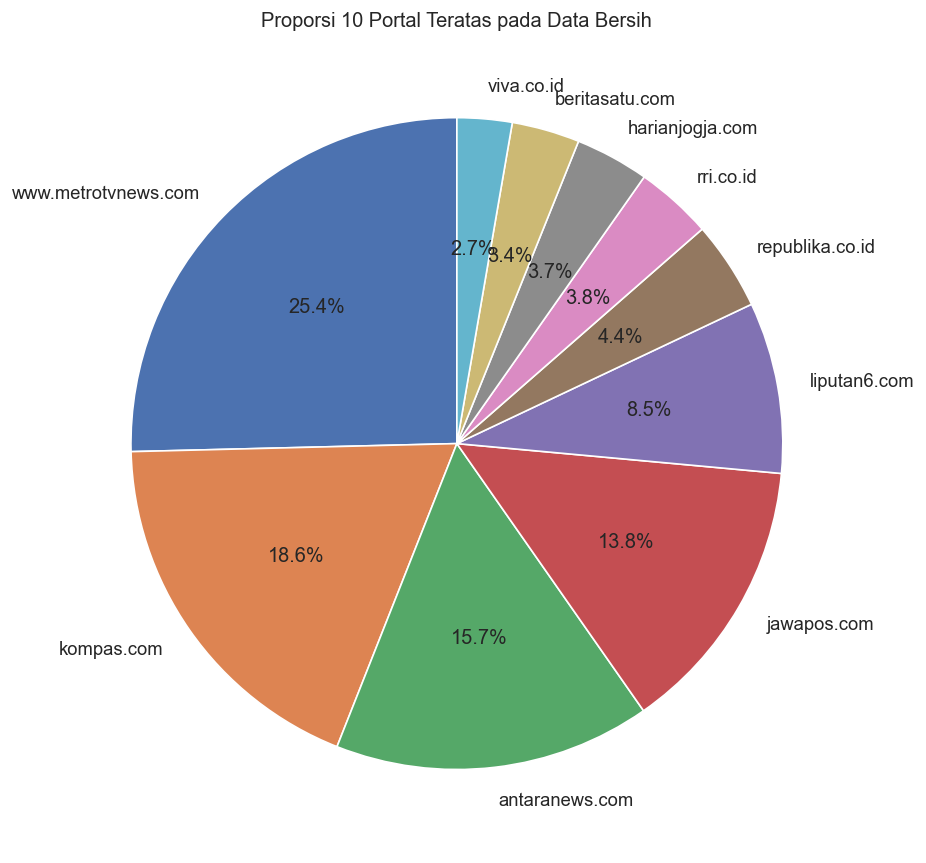

In [5]:
source_frames = {}
for name, df in [
    ("raw", newswatch_long),
    ("artikel_unik", articles),
    ("preprocessed", preprocessed),
    ("clean", clean),
    ("indonesia", indonesia),
    ("prompt", prompt),
]:
    col = "source"
    source_frames[name] = df[col].fillna("(kosong)").value_counts().rename(name)

source_compare = pd.concat(source_frames.values(), axis=1).fillna(0).astype(int)
source_compare["total_tahap"] = source_compare.sum(axis=1)
display(source_compare.sort_values("prompt", ascending=False).head(30))

top = source_compare.sort_values("prompt", ascending=False).head(15)
top[["raw","artikel_unik","preprocessed","clean","indonesia","prompt"]].plot(
    kind="bar", figsize=(14, 7), width=0.82
)
plt.title("Distribusi Portal Berita pada 15 Portal Teratas")
plt.xlabel("Portal berita")
plt.ylabel("Jumlah artikel")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

portal_pie = clean["source"].fillna("(kosong)").value_counts().head(10)
portal_pie.plot.pie(autopct="%1.1f%%", figsize=(8, 8), startangle=90)
plt.title("Proporsi 10 Portal Teratas pada Data Bersih")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 5. Distribusi Waktu

,bulan,jumlah
0,2024-01,11
1,2024-02,10
2,2024-03,28
3,2024-04,37
4,2024-05,15
5,2024-06,8
6,2024-07,12
7,2024-08,24
8,2024-09,29
9,2024-10,12


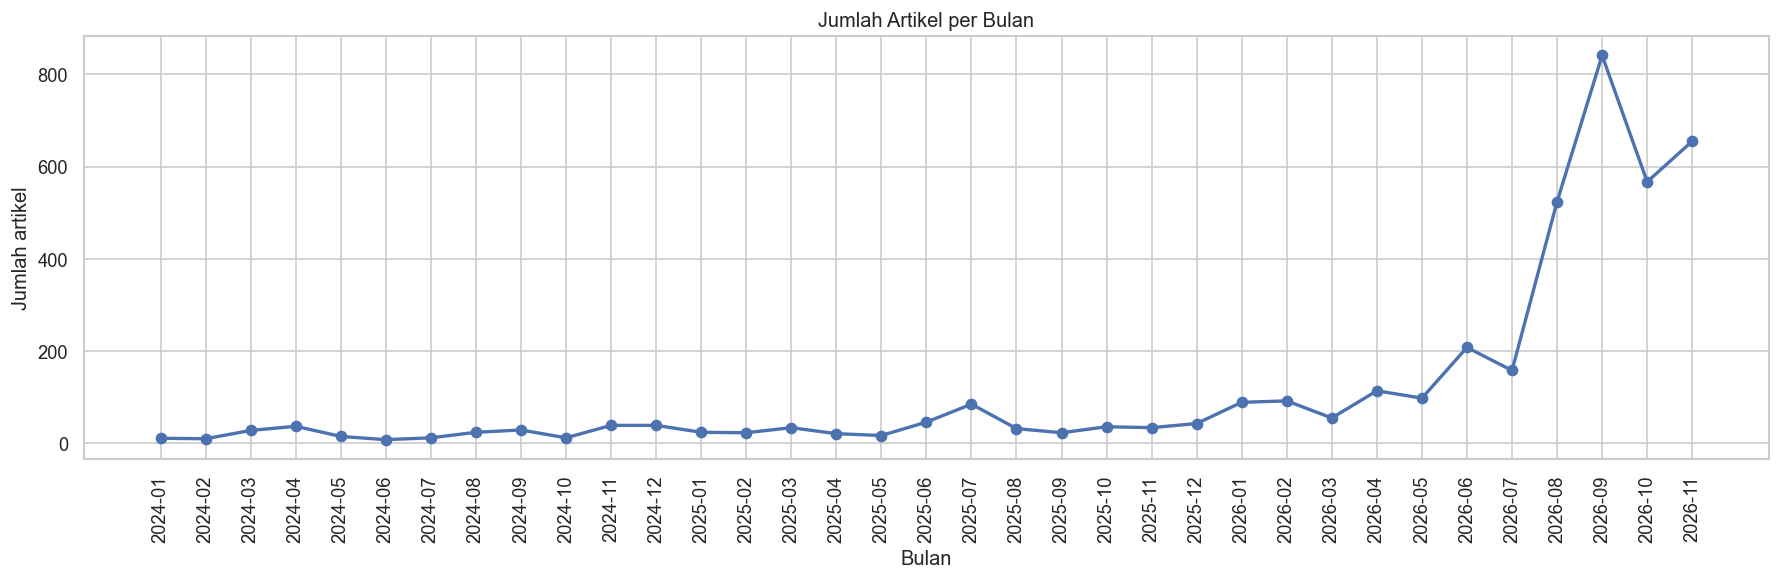

,tahun,jumlah
0,2024,264
1,2025,418
2,2026,3401


Rentang tanggal: 2024-01-01 hingga 2026-11-18


In [6]:
date_col = "publish_date_normalized" if "publish_date_normalized" in clean.columns else "publish_date"
clean_dates = pd.to_datetime(clean[date_col], errors="coerce")
monthly = clean_dates.dt.to_period("M").astype(str).value_counts().sort_index()
monthly_df = monthly.rename_axis("bulan").reset_index(name="jumlah")
display(monthly_df)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(monthly_df["bulan"], monthly_df["jumlah"], marker="o", linewidth=2)
ax.set_title("Jumlah Artikel per Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah artikel")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

yearly = clean_dates.dt.year.value_counts().sort_index()
yearly_df = yearly.rename_axis("tahun").reset_index(name="jumlah")
display(yearly_df)

print("Rentang tanggal:",
      clean_dates.min().strftime("%Y-%m-%d") if clean_dates.notna().any() else None,
      "hingga",
      clean_dates.max().strftime("%Y-%m-%d") if clean_dates.notna().any() else None)

## 6. Distribusi Bahasa

,bahasa,jumlah,persen
0,id,4013,98.285574
1,und,40,0.979672
2,en,30,0.734754


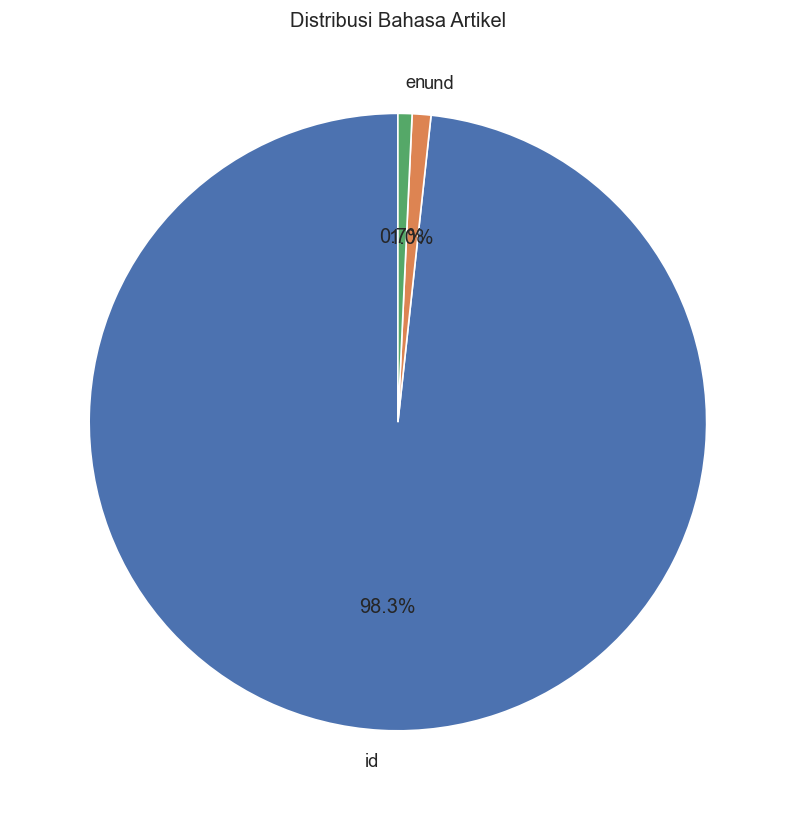

,confidence
count,4083.000000
mean,0.987218
std,0.093437
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


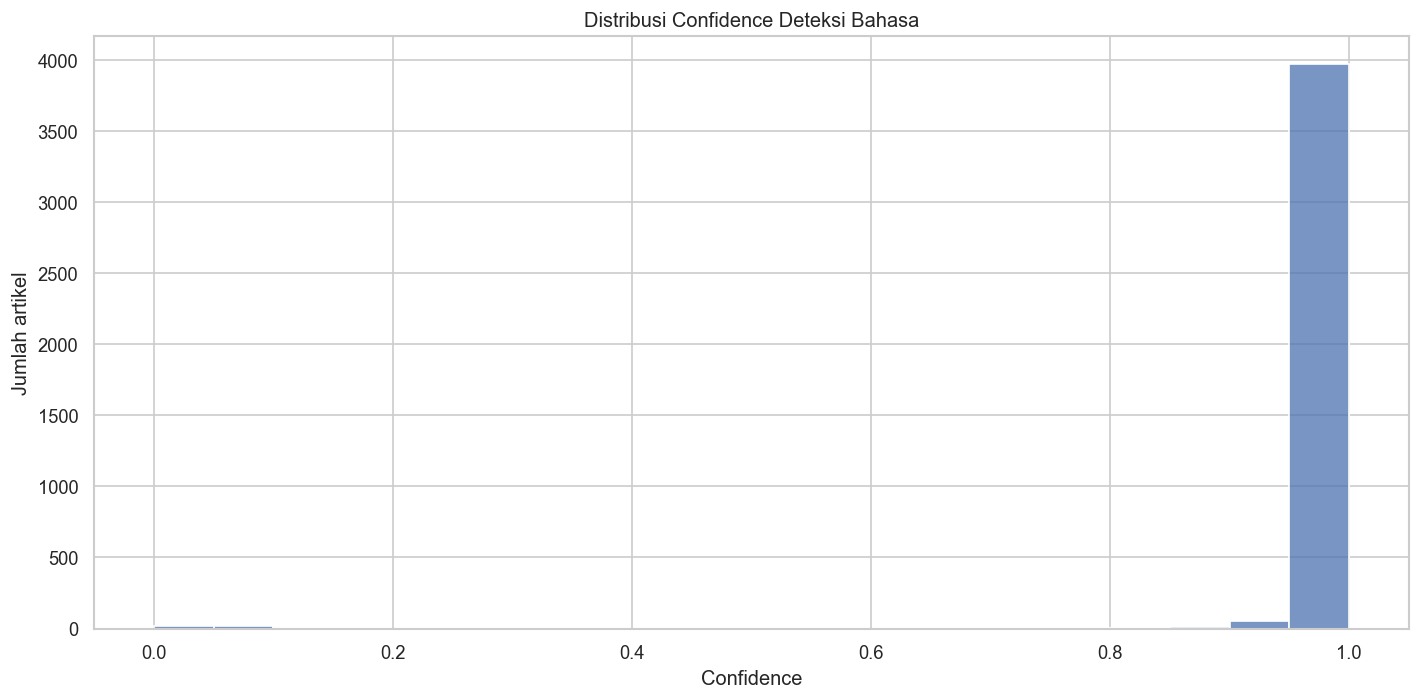

In [7]:
language_col = "language_code" if "language_code" in clean.columns else None
if language_col:
    lang = clean[language_col].fillna("(kosong)").value_counts().rename_axis("bahasa").reset_index(name="jumlah")
    lang["persen"] = 100 * lang["jumlah"] / len(clean)
    display(lang)

    lang.set_index("bahasa")["jumlah"].plot.pie(
        autopct="%1.1f%%", figsize=(7, 7), startangle=90
    )
    plt.title("Distribusi Bahasa Artikel")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

if "language_confidence" in clean.columns:
    display(clean["language_confidence"].describe().to_frame("confidence"))
    sns.histplot(clean["language_confidence"].dropna(), bins=20)
    plt.title("Distribusi Confidence Deteksi Bahasa")
    plt.xlabel("Confidence")
    plt.ylabel("Jumlah artikel")
    plt.tight_layout()
    plt.show()

## 7. Profil QC dan Panjang Teks

,status,jumlah
0,pass,4083


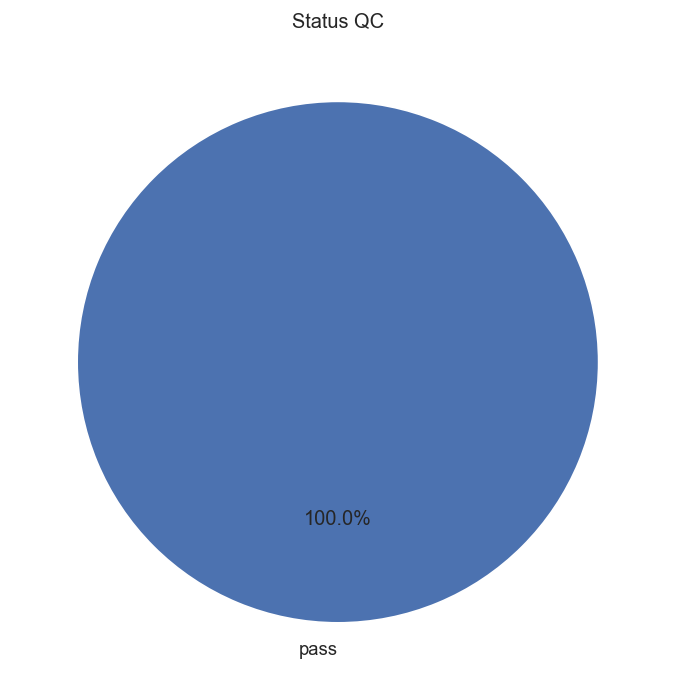

,count,mean,std,min,25%,50%,75%,95%,max
title_length,4083.0,69.280186,14.440280,21.0,60.0,68.0,78.0,96.0,125.0
content_length,4083.0,2788.410972,3772.191599,127.0,929.0,2016.0,3147.5,8039.4,76179.0
content_word_count,4083.0,385.094538,511.472914,19.0,130.0,279.0,434.5,1114.7,10186.0


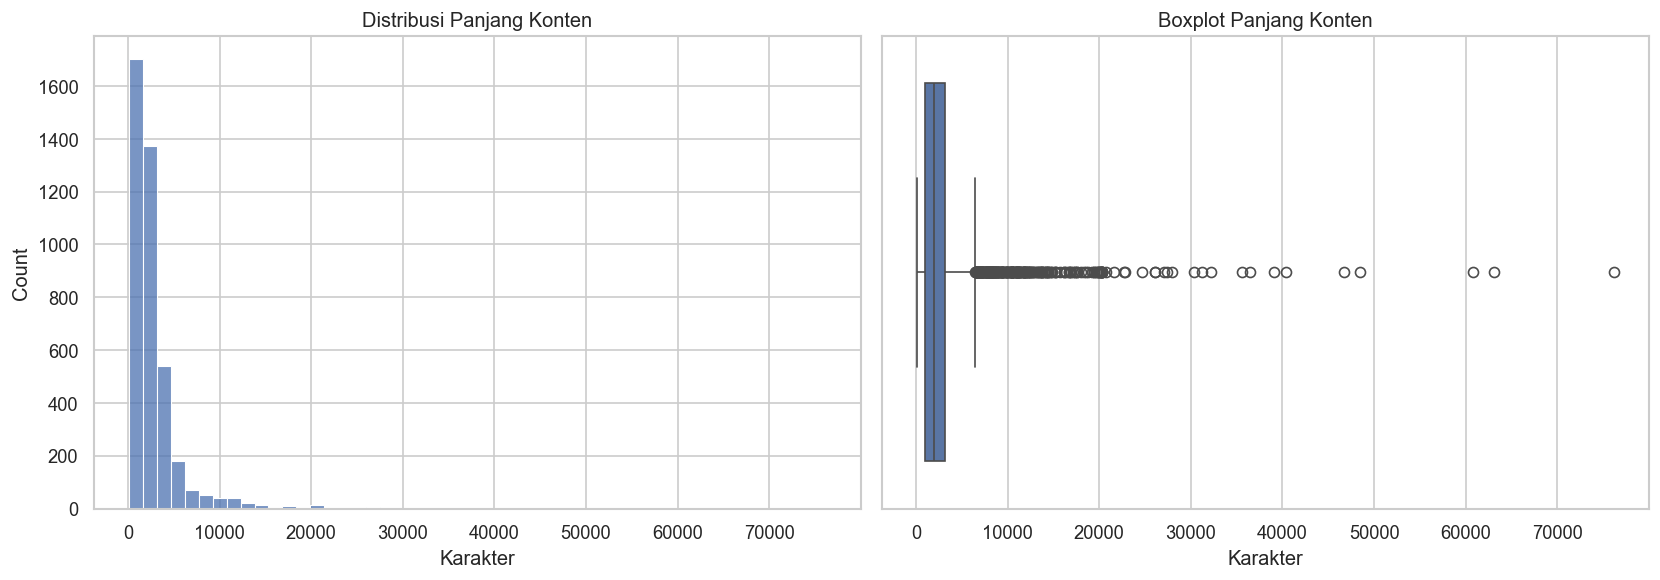

,kolom,missing,persen
0,scraped_at,4083,100.000000
1,content_clean,4083,100.000000
2,duplicate_of,4081,99.951016
3,qc_flags,4079,99.902033
4,category,1,0.024492


,qc_flag,jumlah
0,repeated_content_hash,4
1,same_content_different_urls,4


In [8]:
qc_status = preprocessed["qc_status"].value_counts().rename_axis("status").reset_index(name="jumlah")
display(qc_status)

qc_status.set_index("status")["jumlah"].plot.pie(
    autopct="%1.1f%%", figsize=(6, 6), startangle=90
)
plt.title("Status QC")
plt.ylabel("")
plt.tight_layout()
plt.show()

length_cols = [c for c in ["title_length", "content_length", "content_word_count"]
               if c in preprocessed.columns]
profiles = preprocessed[length_cols].describe(percentiles=[.25,.5,.75,.95]).T
display(profiles)

if "content_length" in preprocessed.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(preprocessed["content_length"], bins=50, ax=axes[0])
    axes[0].set_title("Distribusi Panjang Konten")
    axes[0].set_xlabel("Karakter")
    sns.boxplot(x=preprocessed["content_length"], ax=axes[1])
    axes[1].set_title("Boxplot Panjang Konten")
    axes[1].set_xlabel("Karakter")
    plt.tight_layout()
    plt.show()

missing = preprocessed.isna().sum()
missing = missing[missing.gt(0)].sort_values(ascending=False)
missing_df = (missing.rename_axis("kolom").reset_index(name="missing"))
missing_df["persen"] = 100 * missing_df["missing"] / len(preprocessed)
display(missing_df)

if "qc_flags" in preprocessed.columns:
    flags = (preprocessed["qc_flags"].fillna("")
             .str.split(";").explode().str.strip())
    flags = flags[flags.ne("")]
    display(flags.value_counts().rename_axis("qc_flag").reset_index(name="jumlah").head(30))

## 8. Perbandingan Sebelum dan Sesudah Pembersihan Teks

,Tahap,Jumlah artikel
0,Raw/consolidasi,4083
1,QC/preprocessed,4083
2,Clean/dedup,4083


,raw,qc,clean
count,4457.000000,4083.000000,4083.000000
mean,2774.448508,2788.410972,2786.782758
std,3686.528297,3772.191599,3770.435557
min,127.000000,127.000000,127.000000
25%,932.000000,929.000000,927.000000
50%,2036.000000,2016.000000,2016.000000
75%,3169.000000,3147.500000,3146.500000
max,76179.000000,76179.000000,76179.000000


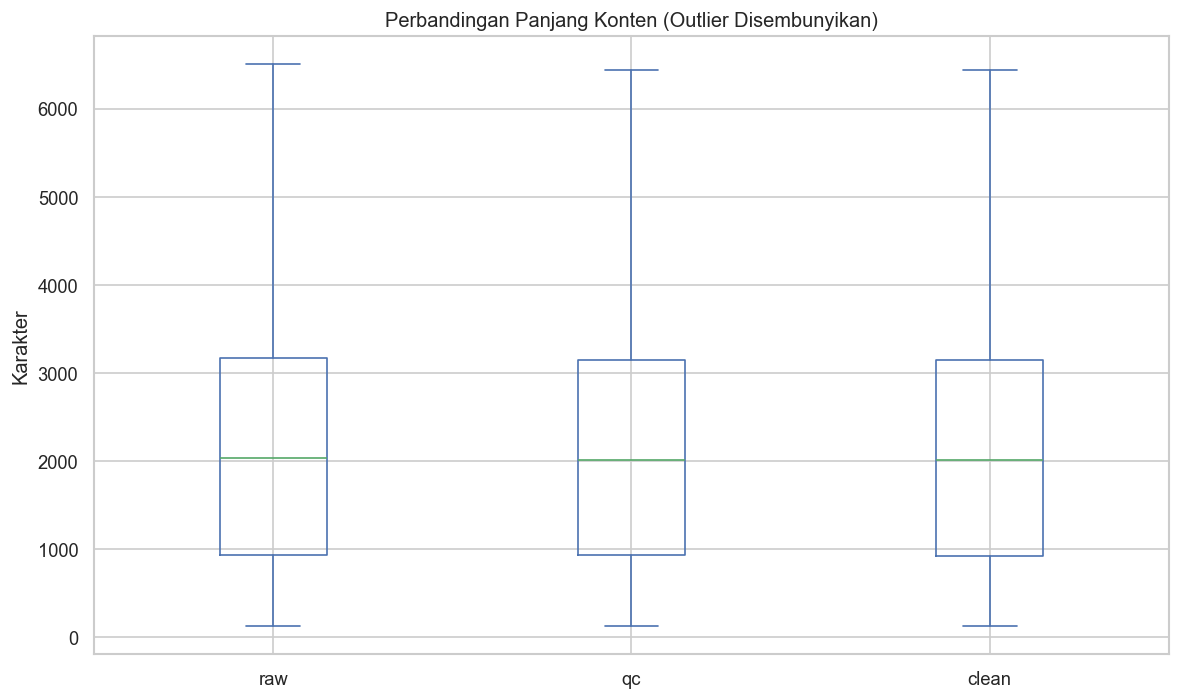

In [9]:
compare = pd.DataFrame({
    "Tahap": ["Raw/consolidasi", "QC/preprocessed", "Clean/dedup"],
    "Jumlah artikel": [len(articles), len(preprocessed), len(clean)],
})
display(compare)

raw_lengths = newswatch_long["content"].fillna("").astype(str).str.len()
qc_lengths = preprocessed["content_cleaned"].fillna("").astype(str).str.len()
clean_lengths = clean["content_clean"].fillna("").astype(str).str.len() if "content_clean" in clean.columns else pd.Series(dtype=float)

length_compare = pd.DataFrame({
    "raw": raw_lengths,
}).describe()
length_compare["qc"] = qc_lengths.describe()
if len(clean_lengths):
    length_compare["clean"] = clean_lengths.describe()
display(length_compare)

to_plot = pd.DataFrame({
    "raw": raw_lengths,
    "qc": qc_lengths,
    "clean": clean_lengths if len(clean_lengths) else pd.Series(dtype=float),
})
to_plot.plot(kind="box", figsize=(10, 6), showfliers=False)
plt.title("Perbandingan Panjang Konten (Outlier Disembunyikan)")
plt.ylabel("Karakter")
plt.tight_layout()
plt.show()

## 9. Profil Duplikasi dan Near-Duplicate

In [10]:
with open(DATA / "interim/deduplication/quality_report.json", encoding="utf-8") as f:
    dedup_report = json.load(f)

dedup_metrics = dedup_report["metrics"]
display(pd.DataFrame([
    ("Artikel input dedup", dedup_metrics["input_articles"]),
    ("Artikel dengan duplicate_of", dedup_metrics["articles_with_duplicate_of"]),
    ("Relasi duplikat tepat", dedup_metrics["exact_duplicate_relations"]),
    ("Pasangan kandidat near-duplikat", dedup_metrics["near_duplicate_candidate_pairs"]),
    ("Relasi near-duplikat ditetapkan", dedup_metrics["near_duplicate_relations_assigned"]),
    ("Artikel prompt", dedup_metrics["articles_in_prompt_output"]),
], columns=["Metrik", "Nilai"]))

if "duplicate_type" in clean.columns:
    dup_type = clean["duplicate_type"].fillna("(bukan duplikat)").value_counts()
    display(dup_type.rename_axis("tipe_duplikat").reset_index(name="jumlah"))

duplicate_pairs = read_csv("interim/deduplication/duplicate_pairs.csv")
near_review = read_csv("interim/deduplication/near_duplicate_manual_review.csv")
print("Jumlah pasangan duplicate_pairs:", len(duplicate_pairs))
print("Jumlah baris near_duplicate manual review:", len(near_review))
display(duplicate_pairs.head(10))
display(near_review.head(10))

,Metrik,Nilai
0,Artikel input dedup,4083
1,Artikel dengan duplicate_of,2
2,Relasi duplikat tepat,2
3,Pasangan kandidat near-duplikat,20
4,Relasi near-duplikat ditetapkan,0
5,Artikel prompt,4051


,tipe_duplikat,jumlah
0,(bukan duplikat),4081
1,exact_content_hash,2


Jumlah pasangan duplicate_pairs: 22
Jumlah baris near_duplicate manual review: 20


,article_id,duplicate_of,duplicate_type,similarity,review_status,title,duplicate_title,url_normalized,duplicate_url_normalized,query_group,duplicate_query_group
0,5d10f7c72a932be378c8,89de22cb6bd25cfea366,exact_content_hash,1.000000,confirmed_exact,Fakta Mengerikan! Sejumlah Kota Besar di Jawa ...,Faktor Penyebab Pulau Jawa Alami Penurunan Muk...,https://viva.co.id/berita/nasional/1869436-fak...,https://viva.co.id/berita/nasional/1869437-fak...,"[""penurunan_tanah""]","[""penurunan_tanah""]"
1,fc0394ae547a32ef9e65,b3bf2655cbfb798a7d1f,exact_content_hash,1.000000,confirmed_exact,Cuaca Indonesia 30 November: Mayoritas Daerah ...,Prakiraan Cuaca Indonesia 30 November: Mayorit...,https://metrotvnews.com/play/kqYCd26B-cuaca-in...,https://metrotvnews.com/read/N0BC1AmW-prakiraa...,"[""tsunami""]","[""tsunami""]"
2,fee39eef95d29b3c4f70,364df6b969fa9a740b15,near_duplicate,0.963733,pending,"Kunjungan ke Bali, Megawati Soroti Parahnya Ab...",Megawati soroti perubahan iklim dalam penangan...,https://jawapos.com/berita-daerah/2610110322/k...,https://antaranews.com/berita/5781152/megawati...,"[""abrasi_pantai""]","[""abrasi_pantai""]"
3,57814633de875a5c5ee2,07c4581b733b2460780d,near_duplicate,0.961391,pending,"Balita 2,7 Tahun di Aceh Tengah Meninggal Tert...",Satu balita meninggal dunia akibat tertimbun l...,https://suara.com/news/2026/11/15/172850/balit...,https://antaranews.com/berita/5855707/satu-bal...,"[""tanah_longsor""]","[""tanah_longsor""]"
4,2a63448549a9bd5d5f25,09a8e8f714b895ec5343,near_duplicate,0.956239,pending,Warga Terdampak Bencana Tanah Bergerak di Breb...,Tanah Bergerak di Brebes Masih Rentan,https://news.republika.co.id/berita/sv7wdn416/...,https://rejogja.republika.co.id/berita/svc48s2...,"[""tanah_longsor""]","[""tanah_longsor""]"
5,75e4b6e4e68a7dfcbedc,1d7ff975d69b11d2d9ba,near_duplicate,0.952188,pending,"Tragis, 2 Petugas Tewas Diduga Hirup Gas Berac...","Tragis, 2 Petugas Telkom Tewas Diduga Hirup Ga...",https://news.okezone.com/read/2024/04/28/525/3...,https://daerah.sindonews.com/read/1367541/701/...,"[""semburan_gas_lumpur""]","[""semburan_gas_lumpur""]"
6,4f3d66ec515d90627f79,39c28d9de9d2e9c7e65d,near_duplicate,0.951524,pending,Badan Geologi Petakan 4 Wilayah di Sulteng Ber...,"Waspada, Badan Geologi petakan 4 wilayah Sulte...",https://nasional.kompas.com/read/2026/06/19/15...,https://antaranews.com/berita/5614655/waspada-...,"[""likuefaksi""]","[""gempabumi"", ""likuefaksi""]"
7,ab80be5a0021f0a90507,237fba9a9be8ea3d2fa4,near_duplicate,0.943376,pending,Status Gunung Lewotobi Laki-Laki di Flotim nai...,Status Gunung Lewotobi Laki-Laki Naik Jadi Awas,https://antaranews.com/berita/4726185/status-g...,https://news.harianjogja.com/r-1207845/status-...,"[""semburan_gas_lumpur""]","[""semburan_gas_lumpur""]"
8,2ed6f1775aa3345871ea,172bccfdec8c35dcd51a,near_duplicate,0.940799,pending,Badan Geologi: Status Gunung Anak Krakatau Tur...,Status Gunung Anak Krakatau turun dari Siaga m...,https://nasional.kompas.com/read/2026/09/22/05...,https://antaranews.com/berita/5751925/status-g...,"[""tsunami""]","[""tsunami""]"
9,95197c8b0204303db137,57814633de875a5c5ee2,near_duplicate,0.926554,pending,Detik-detik Balita Tertimbun Longsor di Aceh T...,"Balita 2,7 Tahun di Aceh Tengah Meninggal Tert...",https://liputan6.com/regional/read/8335774/det...,https://suara.com/news/2026/11/15/172850/balit...,"[""tanah_longsor""]","[""tanah_longsor""]"


,article_id,candidate_article_id,similarity,title,candidate_title,content_excerpt,candidate_content_excerpt,manual_review_status,manual_review_notes
0,364df6b969fa9a740b15,fee39eef95d29b3c4f70,0.963733,Megawati soroti perubahan iklim dalam penangan...,"Kunjungan ke Bali, Megawati Soroti Parahnya Ab...","Ingat, ancaman dari global warming, pencairan ...",Presiden Ke-5 RI sekaligus Ketua Dewan Pengara...,pending,NaN
1,07c4581b733b2460780d,57814633de875a5c5ee2,0.961391,Satu balita meninggal dunia akibat tertimbun l...,"Balita 2,7 Tahun di Aceh Tengah Meninggal Tert...",Jenazah korban longsor tersebut ditemukan di k...,"Suara.com - Salah seorang balita berusia 2,7 t...",pending,NaN
2,09a8e8f714b895ec5343,2a63448549a9bd5d5f25,0.956239,Tanah Bergerak di Brebes Masih Rentan,Warga Terdampak Bencana Tanah Bergerak di Breb...,"REPUBLIKA.CO.ID, SEMARANG -- Kepala Badan Pena...","REPUBLIKA.CO.ID, SEMARANG -- Kepala Badan Pena...",pending,NaN
3,1d7ff975d69b11d2d9ba,75e4b6e4e68a7dfcbedc,0.952188,"Tragis, 2 Petugas Telkom Tewas Diduga Hirup Ga...","Tragis, 2 Petugas Tewas Diduga Hirup Gas Berac...",BANDUNG - Dua petugas Telkom tewas diduga akib...,BANDUNG - Dua petugas Telkom tewas diduga akib...,pending,NaN
4,39c28d9de9d2e9c7e65d,4f3d66ec515d90627f79,0.951524,"Waspada, Badan Geologi petakan 4 wilayah Sulte...",Badan Geologi Petakan 4 Wilayah di Sulteng Ber...,Wilayah yang perlu mendapat perhatian antara l...,"JAKARTA, Badan Geologi Kementerian Energi dan ...",pending,NaN
5,237fba9a9be8ea3d2fa4,ab80be5a0021f0a90507,0.943376,Status Gunung Lewotobi Laki-Laki Naik Jadi Awas,Status Gunung Lewotobi Laki-Laki di Flotim nai...,Petugas SAR gabungan melakukan evakuasi korban...,Labuan Bajo (ANTARA) - Badan Geologi Kementeri...,pending,NaN
6,172bccfdec8c35dcd51a,2ed6f1775aa3345871ea,0.940799,Status Gunung Anak Krakatau turun dari Siaga m...,Badan Geologi: Status Gunung Anak Krakatau Tur...,Jakarta (ANTARA) - Badan Geologi Kementerian E...,"JAKARTA, Badan Geologi Kementerian Energi dan ...",pending,NaN
7,57814633de875a5c5ee2,95197c8b0204303db137,0.926554,"Balita 2,7 Tahun di Aceh Tengah Meninggal Tert...",Detik-detik Balita Tertimbun Longsor di Aceh T...,"Suara.com - Salah seorang balita berusia 2,7 t...","Liputan6.com, Jakarta - Longsor di kawasan Sim...",pending,NaN
8,4f3d66ec515d90627f79,fe00520f4895becd12b7,0.926408,Badan Geologi Petakan 4 Wilayah di Sulteng Ber...,Badan Geologi Sebut 4 Wilayah di Sulteng Berpo...,"JAKARTA, Badan Geologi Kementerian Energi dan ...","JAKARTA, Badan Geologi Kementerian Energi dan ...",pending,NaN
9,0e273ab2fe0cb0b5fb82,8cc2613305ad9f32b5e2,0.924261,"Hasil Investigasi Pemprov Jateng, Tanah Berger...",Pemprov Jateng: Tanah bergerak di Tegal karena...,"JAKARTA, Kepala Dinas Energi dan Sumber Daya M...",Semarang (ANTARA) - Pemerintah Provinsi Jawa T...,pending,NaN


## 10. Profil Gold Set

,jenis_bencana,jumlah,persen
0,gunungapi,32,16.0
1,gempabumi,60,30.0
2,tsunami,30,15.0
3,tanah_longsor,25,12.5
4,likuefaksi,17,8.5
5,abrasi_pantai,22,11.0
6,penurunan_tanah,27,13.5
7,semburan_gas_lumpur,15,7.5


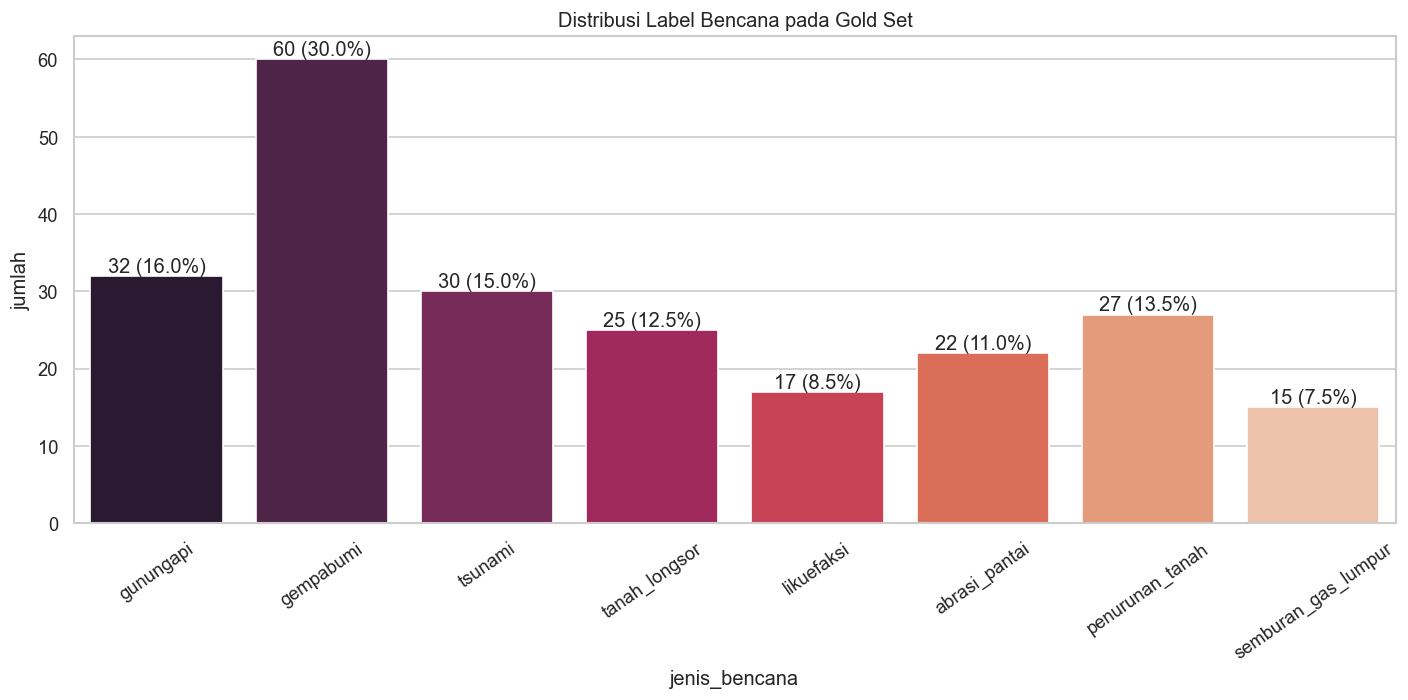

,relevant,jumlah
0,yes,155
1,no,45


,ketidakpastian,jumlah
0,low,197
1,medium,3


,perkiraan_event,jumlah
0,1,124
1,0,45
2,>1,31


Validasi bukti kutipan: 155 dari 155 artikel relevan


In [11]:
gold_hazard_counts = pd.DataFrame({
    "jenis_bencana": HAZARDS,
    "jumlah": [goldset[c].fillna("").eq("yes").sum() for c in HAZARDS],
})
gold_hazard_counts["persen"] = 100 * gold_hazard_counts["jumlah"] / len(goldset)
display(gold_hazard_counts)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=gold_hazard_counts, x="jenis_bencana", y="jumlah", ax=ax, palette="rocket")
ax.set_title("Distribusi Label Bencana pada Gold Set")
ax.tick_params(axis="x", rotation=35)
for i, row in gold_hazard_counts.iterrows():
    ax.text(i, row["jumlah"], f"{row['jumlah']} ({row['persen']:.1f}%)",
            ha="center", va="bottom")
plt.tight_layout()
plt.show()

gold_relevant = goldset["relevant"].fillna("").value_counts().rename_axis("relevant").reset_index(name="jumlah")
display(gold_relevant)

uncertainty = goldset["goldset_uncertainty"].fillna("(kosong)").value_counts().rename_axis("ketidakpastian").reset_index(name="jumlah")
display(uncertainty)

event_count = goldset["event_report_count"].fillna("(kosong)").astype(str).value_counts().rename_axis("perkiraan_event").reset_index(name="jumlah")
display(event_count)

print("Validasi bukti kutipan:",
      int(goldset.loc[goldset["relevant"].eq("yes"), "evidence_text"].fillna("").ne("").sum()),
      "dari",
      int(goldset["relevant"].eq("yes").sum()),
      "artikel relevan")

## 11. Analisis Silang

hazard,abrasi_pantai,gempabumi,gunungapi,likuefaksi,penurunan_tanah,semburan_gas_lumpur,tanah_longsor,tsunami
source,,,,,,,,
www.metrotvnews.com,64,339,123,0,19,32,114,336
kompas.com,77,299,48,31,0,18,132,242
antaranews.com,20,165,89,70,38,39,30,193
jawapos.com,3,323,169,0,1,1,25,22
liputan6.com,15,72,64,2,7,21,102,42
republika.co.id,12,40,28,2,5,3,60,19
rri.co.id,20,0,0,33,12,43,0,36
harianjogja.com,24,0,0,13,2,6,0,95
beritasatu.com,8,0,39,13,11,19,12,31


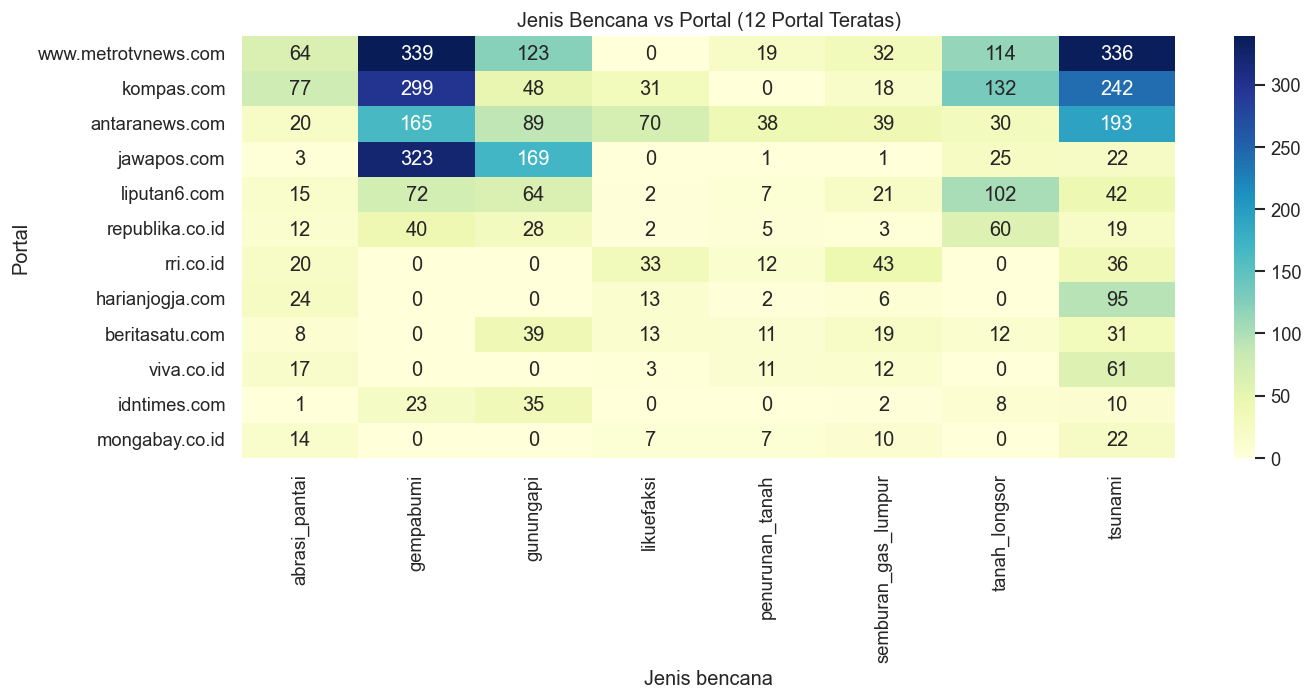

,Nilai
rentang_awal,2024-01-01 12:50:00
rentang_akhir,2026-11-18 11:33:00
artikel_indonesia,4053


In [12]:
# Keterkaitan jenis bencana dengan portal teratas
clean_hazard = pd.DataFrame({
    "source": clean["source"].fillna("(kosong)"),
})
for i, hazard in enumerate(HAZARDS):
    pass

# Query_group diluaskan menjadi satu baris per artikel-kelas
cross = clean[["article_id","source","query_group","publish_date_normalized"]].copy()
cross["hazard"] = cross["query_group"].apply(parse_query_groups)
cross = cross.explode("hazard")
cross = cross[cross["hazard"].isin(HAZARDS)]

cross_table = pd.crosstab(cross["source"], cross["hazard"])
top_sources = cross["source"].value_counts().head(12).index
cross_top = cross_table.loc[top_sources]
display(cross_top)

sns.heatmap(cross_top, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Jenis Bencana vs Portal (12 Portal Teratas)")
plt.xlabel("Jenis bencana")
plt.ylabel("Portal")
plt.tight_layout()
plt.show()

# Ringkasan kalender untuk Indonesia
ind_dates = pd.to_datetime(indonesia["publish_date_normalized"], errors="coerce")
display(pd.DataFrame({
    "rentang_awal": [ind_dates.min()],
    "rentang_akhir": [ind_dates.max()],
    "artikel_indonesia": [len(indonesia)],
}).T.rename(columns={0:"Nilai"}))

## 12. Pemeriksaan Integritas dan Keluaran Ringkas

In [13]:
integrity = pd.DataFrame([
    ("Raw baris", sum(len(df) for df in raw.values())),
    ("Artikel unik URL", articles["article_id"].nunique()),
    ("Duplikat article_id di artikel unik", articles["article_id"].duplicated().sum()),
    ("URL kosong pada artikel unik", articles["url_normalized"].fillna("").eq("").sum()),
    ("Content kosong pada artikel unik", articles["content"].fillna("").eq("").sum()),
    ("QC pass", (preprocessed["qc_status"] == "pass").sum()),
    ("QC non-pass", (preprocessed["qc_status"] != "pass").sum()),
    ("Bahasa id", (clean["language_code"] == "id").sum() if "language_code" in clean else np.nan),
    ("Bahasa en", (clean["language_code"] == "en").sum() if "language_code" in clean else np.nan),
    ("Bahasa und", (clean["language_code"] == "und").sum() if "language_code" in clean else np.nan),
    ("Gold set rows", len(goldset)),
], columns=["Pemeriksaan", "Nilai"])
display(integrity)

(DATA / "reports").mkdir(exist_ok=True)
stage_counts.to_csv(DATA / "reports/profile_stage_counts.csv", index=False)
hazard_df.to_csv(DATA / "reports/profile_hazard_distribution.csv", index=False)
source_compare.sort_values("prompt", ascending=False).to_csv(DATA / "reports/profile_source_distribution.csv")
monthly_df.to_csv(DATA / "reports/profile_monthly_distribution.csv", index=False)
gold_hazard_counts.to_csv(DATA / "reports/profile_goldset_distribution.csv", index=False)
integrity.to_csv(DATA / "reports/profile_integrity.csv", index=False)

print("Ringkasan CSV disimpan ke:", DATA / "reports")

,Pemeriksaan,Nilai
0,Raw baris,4457
1,Artikel unik URL,4083
2,Duplikat article_id di artikel unik,0
3,URL kosong pada artikel unik,0
4,Content kosong pada artikel unik,0
5,QC pass,4083
6,QC non-pass,0
7,Bahasa id,4013
8,Bahasa en,30
9,Bahasa und,40


Ringkasan CSV disimpan ke: D:\MAGANGHUB BATCH 3\Scraper\geolocation3\data\reports
